In [ ]:
# Montar Drive y verificar artefactos de Guía 9

from google.colab import drive
drive.mount('/content/drive')

import os

# Carpeta raíz del proyecto HRTech
BASE = "/content/drive/MyDrive/Proyecto_datos_ia_HRTech_People_Analytics"

# Crear carpetas si no existen
for carpeta in ["modelos", "documentos", "datos/procesados", "notebooks"]:
    os.makedirs(f"{BASE}/{carpeta}", exist_ok=True)

print("modelos/:")
print(os.listdir(f"{BASE}/modelos"))

print("\ndocumentos/:")
print(os.listdir(f"{BASE}/documentos"))

# Verificación de artefacto crítico
ruta_g9 = f"{BASE}/modelos/modelo_candidato_guia09_hrtech.joblib"

print(
    f"\n{'OK' if os.path.exists(ruta_g9) else 'WARNING'} "
    f".joblib de Guía 9: "
    f"{'encontrado' if os.path.exists(ruta_g9) else 'NO encontrado'}"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
modelos/:
['modelo_optimizado_guia10_hrtech.joblib', 'modelo_candidato_guia09_hrtech.joblib']

documentos/:
['comparacion_final_guia10_hrtech.csv', 'resultados_gridsearch_guia10_hrtech.csv', 'top10_errores_guia10_hrtech.csv', 'metadata_guia10_hrtech.json']

OK .joblib de Guía 9: encontrado


In [ ]:
# Imports y configuración global

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, sys, time, joblib

# Herramientas NUEVAS de la Guía 10
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.model_selection import train_test_split

# Métricas de Guía 9
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.dummy import DummyClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False


print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Semilla:", RANDOM_STATE)

Python: 3.13.18
scikit-learn: 1.6.1
Semilla: 42


In [ ]:

# RECONSTRUIR EL DATASET HRTECH
# Recuperar exactamente los datos utilizados en la Guía 9
# Reconstruir dataset de Guía 8

n = 600

df_g8 = pd.DataFrame({"id_empleado": range(1, n + 1)})

df_g8["departamento"] = np.random.choice(
    ["IT", "RRHH", "Finanzas", "Marketing", "Ventas"], n
)
df_g8["edad"] = np.random.randint(21, 56, n)
df_g8["desempeño"] = np.random.normal(80, 9, n).clip(50, 100).round(0)
df_g8["salario"] = np.random.choice(
    [550, 600, 650, 700, 750, 800, 900, 950], n
)
df_g8["tiempo_empresa_anios"] = np.random.randint(0, 11, n)
df_g8["horas_capacitacion"] = np.random.choice([6, 8, 10, 12], n)
df_g8["satisfaccion"] = np.random.randint(1, 6, n)
df_g8["horas_extra"] = np.random.randint(0, 16, n)
df_g8["curso_aprobado"] = np.random.binomial(1, 0.75, n)

# Fórmula generadora (idéntica a Guía 8)
riesgo = (
    -0.10 * (df_g8["desempeño"] - 80)
    -0.45 * (df_g8["satisfaccion"] - 3)
    -0.15 * (df_g8["horas_capacitacion"] - 9)
    +0.06 * (df_g8["horas_extra"] - 7)
    -0.60 * df_g8["curso_aprobado"]
    +np.random.normal(0, 0.8, n)
)

probabilidad = 1 / (1 + np.exp(-riesgo))
df_g8["requiere_capacitacion"] = np.random.binomial(
    1, probabilidad
)

# One-Hot Encoding
df_modelo = pd.get_dummies(
    df_g8,
    columns=["departamento"],
    drop_first=True,
    dtype=int
)

print(f"Dataset: {df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas")
df_modelo.head(3)

Dataset: 600 filas, 14 columnas


,id_empleado,edad,desempeño,salario,tiempo_empresa_anios,horas_capacitacion,satisfaccion,horas_extra,curso_aprobado,requiere_capacitacion,departamento_IT,departamento_Marketing,departamento_RRHH,departamento_Ventas
0,1,31,84.0,950,2,10,2,1,1,1,0,1,0,0
1,2,55,78.0,700,10,8,4,12,1,0,0,0,0,1
2,3,39,90.0,550,7,10,1,12,1,0,0,0,0,0


In [ ]:
# Features y split estratificado 80/20 + guardián

features = [
    "edad", "desempeño", "salario",
    "tiempo_empresa_anios", "horas_capacitacion",
    "satisfaccion", "horas_extra", "curso_aprobado"
] + [c for c in df_modelo.columns if c.startswith("departamento_")]

X = df_modelo[features]
y = df_modelo["requiere_capacitacion"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y
)

# Guardián del experimento
assert set(X_train.index).isdisjoint(set(X_test.index)), "Hay registros repetidos!!!!"

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Distribución train: {y_train.value_counts(normalize=True).round(2).to_dict()}")
print(f"Distribución test: {y_test.value_counts(normalize=True).round(2).to_dict()}")

OK Modelo de Guía 9 cargado desde Drive

Referencia:
   Baseline → Accuracy: 0.5750 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
   Guía 9   → Accuracy: 0.7083 | Precision: 0.6667 | Recall: 0.6275 | F1: 0.6465


In [ ]:
# Cargar modelo de Guía 9 (con fallback) y calcular referencia

ruta_g9 = f"{BASE}/modelos/modelo_candidato_guia09_hrtech.joblib"

if os.path.exists(ruta_g9):
    modelo_guia9 = joblib.load(ruta_g9)
    print("OK Modelo de Guía 9 cargado desde Drive")
else:
    from sklearn.ensemble import RandomForestClassifier
    modelo_guia9 = RandomForestClassifier(
        random_state=RANDOM_STATE
    ).fit(X_train, y_train)
    print("WARNING .joblib no encontrado. Modelo de referencia reconstruido (RandomForestClassifier).")

# Métricas de referencia en el MISMO test
pred_guia9 = modelo_guia9.predict(X_test)
accuracy_guia9  = accuracy_score(y_test, pred_guia9)
precision_guia9 = precision_score(y_test, pred_guia9)
recall_guia9    = recall_score(y_test, pred_guia9)
f1_guia9        = f1_score(y_test, pred_guia9)

# Baseline como piso absoluto
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_base = baseline.predict(X_test)
accuracy_base  = accuracy_score(y_test, pred_base)
precision_base = precision_score(y_test, pred_base, zero_division=0)
recall_base    = recall_score(y_test, pred_base, zero_division=0)
f1_base        = f1_score(y_test, pred_base, zero_division=0)

print("\nReferencia:")
print(f"   Baseline → Accuracy: {accuracy_base:.4f} | Precision: {precision_base:.4f} | Recall: {recall_base:.4f} | F1: {f1_base:.4f}")
print(f"   Guía 9   → Accuracy: {accuracy_guia9:.4f} | Precision: {precision_guia9:.4f} | Recall: {recall_guia9:.4f} | F1: {f1_guia9:.4f}")

Pipeline(steps=[('imputador', SimpleImputer(strategy='median')),
                ('modelo', RandomForestClassifier(n_jobs=1, random_state=42))])


In [ ]:
# Pipeline — el anti-fuga

# WARNING Cambiar aquí si la familia ganadora en tu Guía 9 fue otra
pipeline = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

print(pipeline)

Combinaciones totales: 36
Entrenamientos esperados (combos × folds): 144


In [ ]:
# Grid de hiperparámetros

param_grid = {
    "modelo__n_estimators":     [100, 200],
    "modelo__max_depth":        [5, 10, None],
    "modelo__min_samples_leaf": [1, 3, 5],
    "modelo__class_weight":    [None, "balanced"]
}

combinaciones = list(ParameterGrid(param_grid))
print(f"Combinaciones totales: {len(combinaciones)}")
print(f"Entrenamientos esperados (combos × folds): {len(combinaciones) * 4}")

Folds de validación estratificada (solo sobre X_train):
  Fold 1: train 360 registros | val 120 registros
  Fold 2: train 360 registros | val 120 registros
  Fold 3: train 360 registros | val 120 registros
  Fold 4: train 360 registros | val 120 registros

OK GridSearchCV configurado. Listo para .fit()


In [ ]:
# Configurar GridSearchCV (NO ejecuta todavía)

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

print("Folds de validación estratificada (solo sobre X_train):")
for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), 1):
    print(f"  Fold {fold}: train {len(idx_tr)} registros | val {len(idx_val)} registros")

busqueda = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

print("\nOK GridSearchCV configurado. Listo para .fit()")

Fitting 4 folds for each of 36 candidates, totalling 144 fits

Tiempo total: 64.76 s
Mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Mejor Recall real en CV: 0.6289


In [ ]:
# Ejecutar la búsqueda (SOLO X_train)

inicio = time.perf_counter()
busqueda.fit(X_train, y_train)   # <-- NUNCA "X, y"
tiempo_total = time.perf_counter() - inicio

print("\n" + "=" * 55)
print(f"Tiempo total: {tiempo_total:.2f} s")
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Mejor Recall real en CV: {busqueda.best_score_:.4f}")
print("=" * 55)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,mean_fit_time,params,Recall_validacion,Recall_entrenamiento,Brecha_Recall
23,1,0.628922,0.060525,0.803612,0.020663,1.696990,"{'modelo__class_weight': 'balanced', 'modelo__...",0.628922,0.803612,0.174690
28,2,0.618725,0.057403,0.848172,0.016883,0.322325,"{'modelo__class_weight': 'balanced', 'modelo__...",0.618725,0.848172,0.229447
22,3,0.613824,0.041196,0.808590,0.021233,0.755152,"{'modelo__class_weight': 'balanced', 'modelo__...",0.613824,0.808590,0.194766
34,3,0.613824,0.053825,0.851462,0.017913,0.669504,"{'modelo__class_weight': 'balanced', 'modelo__...",0.613824,0.851462,0.237638
35,5,0.609020,0.058040,0.859707,0.017308,1.147366,"{'modelo__class_weight': 'balanced', 'modelo__...",0.609020,0.859707,0.250688
29,6,0.608922,0.051414,0.861363,0.012582,0.645876,"{'modelo__class_weight': 'balanced', 'modelo__...",0.608922,0.861363,0.252441
21,7,0.608824,0.060913,0.826714,0.022151,1.354878,"{'modelo__class_weight': 'balanced', 'modelo__...",0.608824,0.826714,0.217891
18,8,0.604020,0.064295,0.858073,0.017225,0.570269,"{'modelo__class_weight': 'balanced', 'modelo__...",0.604020,0.858073,0.254054
19,9,0.599020,0.071056,0.849839,0.015667,1.798510,"{'modelo__class_weight': 'balanced', 'modelo__...",0.599020,0.849839,0.250819
32,10,0.598922,0.074869,0.919092,0.019091,0.336823,"{'modelo__class_weight': 'balanced', 'modelo__...",0.598922,0.919092,0.320170


In [ ]:
# Convertir cv_results_ a tabla analizable

resultados = pd.DataFrame(busqueda.cv_results_)

columnas = ["rank_test_score", "mean_test_score", "std_test_score",
            "mean_train_score", "std_train_score", "mean_fit_time", "params"]
tabla_grid = resultados[columnas].copy()

tabla_grid["Recall_validacion"] = tabla_grid["mean_test_score"]
tabla_grid["Recall_entrenamiento"] = tabla_grid["mean_train_score"]
tabla_grid["Brecha_Recall"] = tabla_grid["Recall_entrenamiento"] - tabla_grid["Recall_validacion"]

tabla_grid.sort_values("rank_test_score").head(10)

,rank_test_score,Recall_validacion,std_test_score,Recall_entrenamiento,Brecha_Recall,mean_fit_time
0,1,0.63,0.06,0.80,0.17,1.70
1,2,0.62,0.06,0.85,0.23,0.32
2,3,0.61,0.04,0.81,0.19,0.76
3,3,0.61,0.05,0.85,0.24,0.67
4,5,0.61,0.06,0.86,0.25,1.15
5,6,0.61,0.05,0.86,0.25,0.65
6,7,0.61,0.06,0.83,0.22,1.35
7,8,0.60,0.06,0.86,0.25,0.57
8,9,0.60,0.07,0.85,0.25,1.80
9,10,0.60,0.07,0.92,0.32,0.34


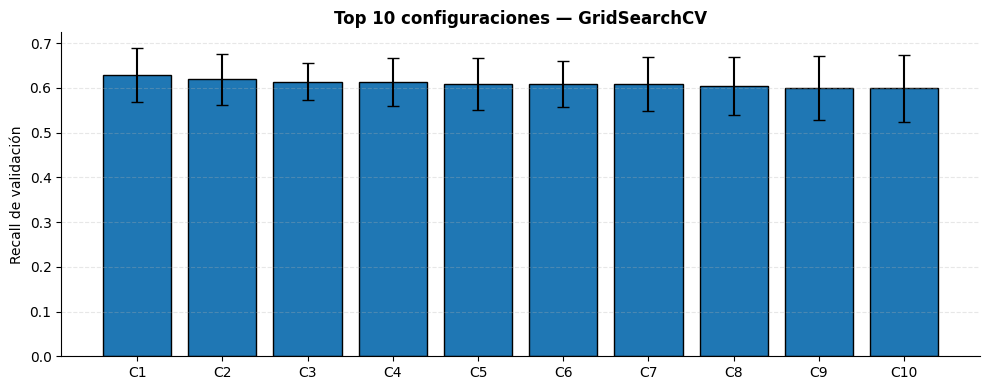

In [ ]:
# Top 10 configuraciones y métricas resumidas

tabla_grid = tabla_grid.sort_values("rank_test_score").reset_index(drop=True)

top10 = tabla_grid.head(10).copy()
top10["config"] = top10["params"].apply(lambda d: dict(d))
top10[["rank_test_score", "Recall_validacion", "std_test_score",
       "Recall_entrenamiento", "Brecha_Recall", "mean_fit_time"]].round(2)

In [ ]:
# Gráfico del top 10 (media ± std)

top = tabla_grid.nlargest(10, "Recall_validacion").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(top)), top["Recall_validacion"],
       yerr=top["std_test_score"], capsize=4, edgecolor="black")
ax.set_xticks(range(len(top)))
ax.set_xticklabels([f"C{i+1}" for i in range(len(top))])
ax.set_ylabel("Recall de validación")
ax.set_title("Top 10 configuraciones — GridSearchCV", fontweight="bold")
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

EVALUACIÓN DEL MODELO OPTIMIZADO EN PRUEBA
Mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Registros de prueba: 120

MÉTRICAS DE CLASIFICACIÓN:
   Accuracy:  0.6833
   Precision: 0.6226
   Recall:    0.6471   <- métrica usada en GridSearchCV
   F1-Score:  0.6346
   ROC-AUC:   0.7582

MÉTRICAS DE ERROR (sobre la probabilidad):
   MAE:  0.4304
   RMSE: 0.4513
   R²:   0.1665

MATRIZ DE CONFUSIÓN:
                    Predicho 0   Predicho 1
   Real 0           TN = 49       FP = 20
   Real 1           FN = 18       TP = 33

Recall en CV: 0.6289  |  Recall en prueba: 0.6471
Diferencia CV - prueba: -0.0181


COMPARACIÓN FINAL — MISMO CONJUNTO DE PRUEBA
                Modelo  Accuracy  Precision  Recall     F1  ROC_AUC    MAE   RMSE      R2
              Baseline    0.5750     0.0000  0.0000 0.0000   0.5000 0.4250 0.6519 -0.7391
Guía 9 (sin optimizar)    0.7083     0.6667  0.6275 0.6465   0.7433 0.4128 0.4495  0.1732
  Guía 10 (optimizado)    0.6833     0.6226  0.6471 0.6346   0.7582 0.4304 0.4513  0.1665

GUÍA 10 vs GUÍA 9
  Métrica  Guía 9  Guía 10  Diferencia ¿Mejoró?
 Accuracy  0.7083   0.6833     -0.0250       No
Precision  0.6667   0.6226     -0.0440       No
   Recall  0.6275   0.6471      0.0196       Sí
       F1  0.6465   0.6346     -0.0118       No
  ROC_AUC  0.7433   0.7582      0.0149       Sí
      MAE  0.4128   0.4304      0.0177       No
     RMSE  0.4495   0.4513      0.0018       No
       R2  0.1732   0.1665     -0.0067       No


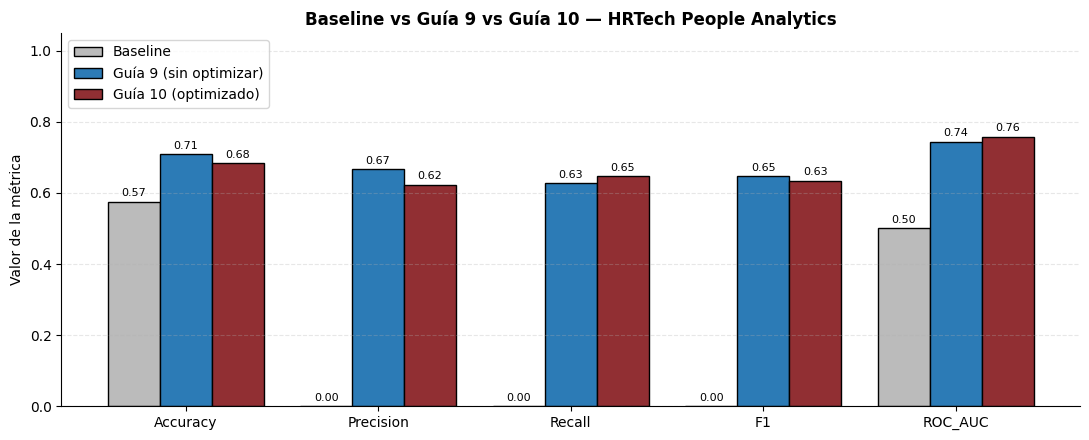


VEREDICTO:
   El modelo optimizado MEJORÓ el Recall en +2.0 puntos porcentuales
   (0.627 -> 0.647): detecta más colaboradores que sí requieren capacitación.
   Cambio en F1: -1.2 puntos | Cambio en Precision: -4.4 puntos


In [ ]:
# Evaluar el modelo optimizado con los datos de prueba
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix

# Mejor pipeline encontrado por GridSearchCV.
# Como refit=True, ya fue reentrenado con TODO X_train usando los mejores parámetros.
modelo_optimizado = busqueda.best_estimator_

# El conjunto de prueba (X_test)
pred_opt = modelo_optimizado.predict(X_test)
prob_opt = modelo_optimizado.predict_proba(X_test)[:, 1]

# Métricas de clasificación (las mismas de la Guía 9)
accuracy_opt  = accuracy_score(y_test, pred_opt)
precision_opt = precision_score(y_test, pred_opt, zero_division=0)
recall_opt    = recall_score(y_test, pred_opt, zero_division=0)
f1_opt        = f1_score(y_test, pred_opt, zero_division=0)
auc_opt       = roc_auc_score(y_test, prob_opt)

# MAE, RMSE y R²: como el problema es de clasificación, se calculan comparando
# la PROBABILIDAD predicha (0 a 1) con el valor real (0 o 1)
mae_opt  = mean_absolute_error(y_test, prob_opt)
rmse_opt = np.sqrt(mean_squared_error(y_test, prob_opt))
r2_opt   = r2_score(y_test, prob_opt)

cm_opt = confusion_matrix(y_test, pred_opt)

print("EVALUACIÓN DEL MODELO OPTIMIZADO EN PRUEBA")
print("=" * 60)
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Registros de prueba: {len(X_test)}")

print("\nMÉTRICAS DE CLASIFICACIÓN:")
print(f"   Accuracy:  {accuracy_opt:.4f}")
print(f"   Precision: {precision_opt:.4f}")
print(f"   Recall:    {recall_opt:.4f}   <- métrica usada en GridSearchCV")
print(f"   F1-Score:  {f1_opt:.4f}")
print(f"   ROC-AUC:   {auc_opt:.4f}")

print("\nMÉTRICAS DE ERROR (sobre la probabilidad):")
print(f"   MAE:  {mae_opt:.4f}")
print(f"   RMSE: {rmse_opt:.4f}")
print(f"   R²:   {r2_opt:.4f}")

print("\nMATRIZ DE CONFUSIÓN:")
print(f"                    Predicho 0   Predicho 1")
print(f"   Real 0           TN = {cm_opt[0, 0]:<8} FP = {cm_opt[0, 1]}")
print(f"   Real 1           FN = {cm_opt[1, 0]:<8} TP = {cm_opt[1, 1]}")

print(f"\nRecall en CV: {busqueda.best_score_:.4f}  |  Recall en prueba: {recall_opt:.4f}")
print(f"Diferencia CV - prueba: {busqueda.best_score_ - recall_opt:+.4f}")

TOP 10 ERRORES ABSOLUTOS MÁS GRANDES — MODELO OPTIMIZADO
 id_empleado  desempeño  satisfaccion  horas_capacitacion  horas_extra  curso_aprobado  real  predicho  probabilidad  error_abs              tipo
         220       86.0             5                  12           10               0     1         0         0.199      0.801 FN (no detectado)
         234       90.0             3                  10            5               0     1         0         0.301      0.699 FN (no detectado)
         545       77.0             2                   6           14               1     0         1         0.692      0.692 FP (falsa alarma)
         178       77.0             1                   8           14               0     0         1         0.669      0.669 FP (falsa alarma)
         160       77.0             2                   8            7               1     0         1         0.668      0.668 FP (falsa alarma)
          10       92.0             1                  10          

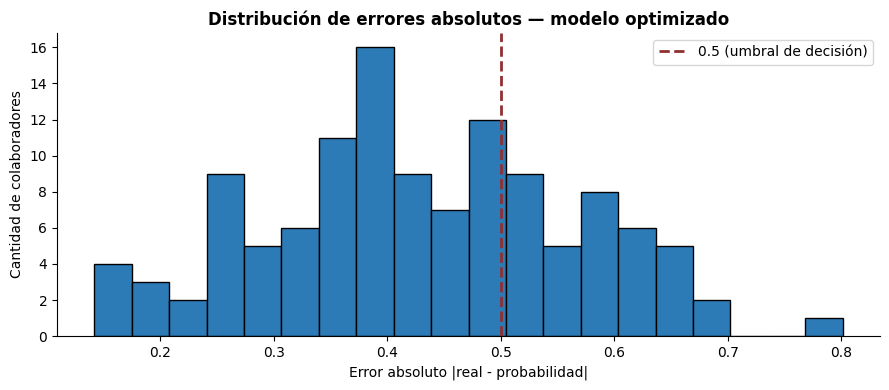

NOTA: un error absoluto > 0.5 significa que el modelo clasificó mal al colaborador.


In [ ]:
# Comparar Baseline, Guía 9 y Guía 10 (mismo conjunto de prueba)

prob_guia9 = modelo_guia9.predict_proba(X_test)[:, 1]
prob_base  = baseline.predict_proba(X_test)[:, 1]

def resumen_metricas(nombre, pred, prob):
    """Calcula todas las métricas de un modelo sobre X_test."""
    return {
        "Modelo":    nombre,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "ROC_AUC":   roc_auc_score(y_test, prob),
        "MAE":       mean_absolute_error(y_test, prob),
        "RMSE":      np.sqrt(mean_squared_error(y_test, prob)),
        "R2":        r2_score(y_test, prob)
    }

comparacion_final = pd.DataFrame([
    resumen_metricas("Baseline",               pred_base,  prob_base),
    resumen_metricas("Guía 9 (sin optimizar)", pred_guia9, prob_guia9),
    resumen_metricas("Guía 10 (optimizado)",   pred_opt,   prob_opt)
])

print("COMPARACIÓN FINAL — MISMO CONJUNTO DE PRUEBA")
print("=" * 100)
print(comparacion_final.round(4).to_string(index=False))

# ¿Mejoró la Guía 10 respecto a la Guía 9? (en MAE y RMSE, menor es mejor)
mayor_es_mejor = {"Accuracy": True, "Precision": True, "Recall": True, "F1": True,
                  "ROC_AUC": True, "MAE": False, "RMSE": False, "R2": True}

g9  = comparacion_final.iloc[1]
g10 = comparacion_final.iloc[2]

tabla_mejora = pd.DataFrame({
    "Métrica": list(mayor_es_mejor.keys()),
    "Guía 9":  [g9[m]  for m in mayor_es_mejor],
    "Guía 10": [g10[m] for m in mayor_es_mejor],
})
tabla_mejora["Diferencia"] = tabla_mejora["Guía 10"] - tabla_mejora["Guía 9"]
tabla_mejora["¿Mejoró?"] = [
    "Sí" if (d > 0 if mayor_es_mejor[m] else d < 0) else ("Igual" if d == 0 else "No")
    for m, d in zip(tabla_mejora["Métrica"], tabla_mejora["Diferencia"])
]

print("\nGUÍA 10 vs GUÍA 9")
print("=" * 60)
print(tabla_mejora.round(4).to_string(index=False))

# Gráfico de barras agrupadas
metricas_graf = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
x = np.arange(len(metricas_graf))
ancho = 0.27
colores = ["#BBBBBB", "#2c7bb6", "#912F33"]

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (_, fila) in enumerate(comparacion_final.iterrows()):
    valores = [fila[m] for m in metricas_graf]
    barras = ax.bar(x + (i - 1) * ancho, valores, ancho, label=fila["Modelo"],
                    color=colores[i], edgecolor="black")
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{v:.2f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metricas_graf)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Baseline vs Guía 9 vs Guía 10 — HRTech People Analytics", fontweight="bold")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

# Veredicto (la métrica principal es Recall, porque fue la usada en GridSearchCV)
mejora_recall = recall_opt - recall_guia9
mejora_f1     = f1_opt - f1_guia9
print("\nVEREDICTO:")
if mejora_recall > 0:
    print(f"   El modelo optimizado MEJORÓ el Recall en {mejora_recall*100:+.1f} puntos porcentuales")
    print(f"   ({recall_guia9:.3f} -> {recall_opt:.3f}): detecta más colaboradores que sí requieren capacitación.")
else:
    print(f"   El modelo optimizado NO mejoró el Recall ({recall_guia9:.3f} -> {recall_opt:.3f}).")
print(f"   Cambio en F1: {mejora_f1*100:+.1f} puntos | Cambio en Precision: {(precision_opt - precision_guia9)*100:+.1f} puntos")

In [ ]:
# Analizar los 10 errores absolutos más grandes

errores_opt = X_test[["desempeño", "satisfaccion", "horas_capacitacion",
                      "horas_extra", "curso_aprobado"]].copy()
errores_opt.insert(0, "id_empleado", df_modelo.loc[X_test.index, "id_empleado"].values)
errores_opt["real"]         = y_test.values
errores_opt["predicho"]     = pred_opt
errores_opt["probabilidad"] = prob_opt.round(3)

# Error absoluto = qué tan lejos quedó la probabilidad del valor real
errores_opt["error_abs"] = (errores_opt["real"] - errores_opt["probabilidad"]).abs().round(3)
errores_opt["tipo"] = np.where(
    errores_opt["real"] == errores_opt["predicho"], "Acierto",
    np.where(errores_opt["real"] == 1, "FN (no detectado)", "FP (falsa alarma)")
)

top10_errores = errores_opt.nlargest(10, "error_abs").reset_index(drop=True)

print("TOP 10 ERRORES ABSOLUTOS MÁS GRANDES — MODELO OPTIMIZADO")
print("=" * 110)
print(top10_errores.to_string(index=False))

print("\nRESUMEN DEL TOP 10:")
print(f"   Falsos negativos (FN): {(top10_errores['tipo'] == 'FN (no detectado)').sum()}")
print(f"   Falsos positivos (FP): {(top10_errores['tipo'] == 'FP (falsa alarma)').sum()}")
print(f"   Error absoluto promedio del top 10:      {top10_errores['error_abs'].mean():.3f}")
print(f"   Error absoluto promedio de toda la prueba: {errores_opt['error_abs'].mean():.3f}")

# ¿En qué se parecen los casos con más error? Comparar promedios
vars_perfil = ["desempeño", "satisfaccion", "horas_capacitacion", "horas_extra", "curso_aprobado"]
perfil = pd.DataFrame({
    "Top 10 errores":   top10_errores[vars_perfil].mean(),
    "Todo el test":     errores_opt[vars_perfil].mean()
}).round(2)

print("\nPERFIL PROMEDIO: TOP 10 ERRORES vs TODO EL CONJUNTO DE PRUEBA")
print(perfil.to_string())

# Distribución de los errores absolutos
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(errores_opt["error_abs"], bins=20, color="#2c7bb6", edgecolor="black")
ax.axvline(0.5, color="#912F33", linestyle="--", linewidth=2, label="0.5 (umbral de decisión)")
ax.set_xlabel("Error absoluto |real - probabilidad|")
ax.set_ylabel("Cantidad de colaboradores")
ax.set_title("Distribución de errores absolutos — modelo optimizado", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

print("NOTA: un error absoluto > 0.5 significa que el modelo clasificó mal al colaborador.")

ARCHIVOS GUARDADOS
  modelos/modelo_optimizado_guia10_hrtech.joblib             745.9 KB
  documentos/comparacion_final_guia10_hrtech.csv               0.5 KB
  documentos/resultados_gridsearch_guia10_hrtech.csv           9.8 KB
  documentos/top10_errores_guia10_hrtech.csv                   0.6 KB
  datos/procesados/predicciones_guia10_hrtech.csv              5.3 KB


In [ ]:
# Evaluar el modelo optimizado con los datos de prueba
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix

# Mejor pipeline encontrado por GridSearchCV.
# Como refit=True, ya fue reentrenado con TODO X_train usando los mejores parámetros.
modelo_optimizado = busqueda.best_estimator_

# El conjunto de prueba (X_test)
pred_opt = modelo_optimizado.predict(X_test)
prob_opt = modelo_optimizado.predict_proba(X_test)[:, 1]

# Métricas de clasificación (las mismas de la Guía 9)
accuracy_opt  = accuracy_score(y_test, pred_opt)
precision_opt = precision_score(y_test, pred_opt, zero_division=0)
recall_opt    = recall_score(y_test, pred_opt, zero_division=0)
f1_opt        = f1_score(y_test, pred_opt, zero_division=0)
auc_opt       = roc_auc_score(y_test, prob_opt)

# MAE, RMSE y R²: como el problema es de clasificación, se calculan comparando
# la PROBABILIDAD predicha (0 a 1) con el valor real (0 o 1)
mae_opt  = mean_absolute_error(y_test, prob_opt)
rmse_opt = np.sqrt(mean_squared_error(y_test, prob_opt))
r2_opt   = r2_score(y_test, prob_opt)

cm_opt = confusion_matrix(y_test, pred_opt)

print("EVALUACIÓN DEL MODELO OPTIMIZADO EN PRUEBA")
print("=" * 60)
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Registros de prueba: {len(X_test)}")

print("\nMÉTRICAS DE CLASIFICACIÓN:")
print(f"   Accuracy:  {accuracy_opt:.4f}")
print(f"   Precision: {precision_opt:.4f}")
print(f"   Recall:    {recall_opt:.4f}   <- métrica usada en GridSearchCV")
print(f"   F1-Score:  {f1_opt:.4f}")
print(f"   ROC-AUC:   {auc_opt:.4f}")

print("\nMÉTRICAS DE ERROR (sobre la probabilidad):")
print(f"   MAE:  {mae_opt:.4f}")
print(f"   RMSE: {rmse_opt:.4f}")
print(f"   R²:   {r2_opt:.4f}")

print("\nMATRIZ DE CONFUSIÓN:")
print(f"                    Predicho 0   Predicho 1")
print(f"   Real 0           TN = {cm_opt[0, 0]:<8} FP = {cm_opt[0, 1]}")
print(f"   Real 1           FN = {cm_opt[1, 0]:<8} TP = {cm_opt[1, 1]}")

print(f"\nRecall en CV: {busqueda.best_score_:.4f}  |  Recall en prueba: {recall_opt:.4f}")
print(f"Diferencia CV - prueba: {busqueda.best_score_ - recall_opt:+.4f}")

METADATOS DEL EXPERIMENTO
{
  "proyecto": "HRTech People Analytics",
  "guia": "Guía 10 - Optimización de hiperparámetros",
  "fecha_ejecucion": "2026-11-18T02:56:55",
  "versiones": {
    "python": "3.13.18",
    "scikit_learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.4.6"
  },
  "random_state": 42,
  "datos": {
    "tipo": "Sintéticos (reconstruidos con la fórmula de la Guía 8)",
    "variable_objetivo": "requiere_capacitacion",
    "n_filas": 600,
    "n_train": 480,
    "n_test": 120,
    "n_features": 12,
    "features": [
      "edad",
      "desempeño",
      "salario",
      "tiempo_empresa_anios",
      "horas_capacitacion",
      "satisfaccion",
      "horas_extra",
      "curso_aprobado",
      "departamento_IT",
      "departamento_Marketing",
      "departamento_RRHH",
      "departamento_Ventas"
    ]
  },
  "busqueda": {
    "metodo": "GridSearchCV",
    "modelo": "RandomForestClassifier (Pipeline con SimpleImputer)",
    "validacion": "StratifiedKFold(n_splits=4

In [ ]:
# Comparar Baseline, Guía 9 y Guía 10

prob_guia9 = modelo_guia9.predict_proba(X_test)[:, 1]
prob_base  = baseline.predict_proba(X_test)[:, 1]

def resumen_metricas(nombre, pred, prob):
    """Calcula todas las métricas de un modelo sobre X_test."""
    return {
        "Modelo":    nombre,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "ROC_AUC":   roc_auc_score(y_test, prob),
        "MAE":       mean_absolute_error(y_test, prob),
        "RMSE":      np.sqrt(mean_squared_error(y_test, prob)),
        "R2":        r2_score(y_test, prob)
    }

comparacion_final = pd.DataFrame([
    resumen_metricas("Baseline",               pred_base,  prob_base),
    resumen_metricas("Guía 9 (sin optimizar)", pred_guia9, prob_guia9),
    resumen_metricas("Guía 10 (optimizado)",   pred_opt,   prob_opt)
])

print("COMPARACIÓN FINAL — MISMO CONJUNTO DE PRUEBA")
print("=" * 100)
print(comparacion_final.round(4).to_string(index=False))

# ¿Mejoró la Guía 10 respecto a la Guía 9? (en MAE y RMSE, menor es mejor)
mayor_es_mejor = {"Accuracy": True, "Precision": True, "Recall": True, "F1": True,
                  "ROC_AUC": True, "MAE": False, "RMSE": False, "R2": True}

g9  = comparacion_final.iloc[1]
g10 = comparacion_final.iloc[2]

tabla_mejora = pd.DataFrame({
    "Métrica": list(mayor_es_mejor.keys()),
    "Guía 9":  [g9[m]  for m in mayor_es_mejor],
    "Guía 10": [g10[m] for m in mayor_es_mejor],
})
tabla_mejora["Diferencia"] = tabla_mejora["Guía 10"] - tabla_mejora["Guía 9"]
tabla_mejora["¿Mejoró?"] = [
    "Sí" if (d > 0 if mayor_es_mejor[m] else d < 0) else ("Igual" if d == 0 else "No")
    for m, d in zip(tabla_mejora["Métrica"], tabla_mejora["Diferencia"])
]

print("\nGUÍA 10 vs GUÍA 9")
print("=" * 60)
print(tabla_mejora.round(4).to_string(index=False))

# Gráfico de barras agrupadas
metricas_graf = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
x = np.arange(len(metricas_graf))
ancho = 0.27
colores = ["#BBBBBB", "#2c7bb6", "#912F33"]

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (_, fila) in enumerate(comparacion_final.iterrows()):
    valores = [fila[m] for m in metricas_graf]
    barras = ax.bar(x + (i - 1) * ancho, valores, ancho, label=fila["Modelo"],
                    color=colores[i], edgecolor="black")
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{v:.2f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metricas_graf)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Baseline vs Guía 9 vs Guía 10 — HRTech People Analytics", fontweight="bold")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

# Veredicto (la métrica principal es Recall, porque fue la usada en GridSearchCV)
mejora_recall = recall_opt - recall_guia9
mejora_f1     = f1_opt - f1_guia9
print("\nVEREDICTO:")
if mejora_recall > 0:
    print(f"   El modelo optimizado MEJORÓ el Recall en {mejora_recall*100:+.1f} puntos porcentuales")
    print(f"   ({recall_guia9:.3f} -> {recall_opt:.3f}): detecta más colaboradores que sí requieren capacitación.")
else:
    print(f"   El modelo optimizado NO mejoró el Recall ({recall_guia9:.3f} -> {recall_opt:.3f}).")
print(f"   Cambio en F1: {mejora_f1*100:+.1f} puntos | Cambio en Precision: {(precision_opt - precision_guia9)*100:+.1f} puntos")

AUDITORÍA FINAL — CHECKLIST
  OK     Train y test sin registros en común
  OK     Train 480 filas / Test 120 filas
  OK     GridSearchCV probó todas las combinaciones (36)
  OK     El modelo optimizado supera al baseline (F1)
  OK     Comparación incluye 3 modelos
  OK     Top 10 errores analizados
  OK     Todos los archivos existen y no están vacíos
  OK     Modelo recargado da las mismas predicciones
  OK     Modelo recargado da las mismas probabilidades
  OK     Metadatos se leen y tienen los mejores parámetros
  OK     Recall de los metadatos coincide con el calculado
  OK     Métricas dentro del rango válido [0, 1]

INVENTARIO DE ARCHIVOS
  modelos/modelo_optimizado_guia10_hrtech.joblib             745.9 KB
  documentos/comparacion_final_guia10_hrtech.csv               0.5 KB
  documentos/resultados_gridsearch_guia10_hrtech.csv           9.8 KB
  documentos/top10_errores_guia10_hrtech.csv                   0.6 KB
  datos/procesados/predicciones_guia10_hrtech.csv              5.3 

In [ ]:
# Guardar los resultados y archivos del modelo
from pathlib import Path

BASE_P = Path(BASE)   # carpeta del proyecto en Drive (definida al inicio de la Guía 10)
(BASE_P / "modelos").mkdir(parents=True, exist_ok=True)
(BASE_P / "documentos").mkdir(parents=True, exist_ok=True)
(BASE_P / "datos" / "procesados").mkdir(parents=True, exist_ok=True)

# 1) Modelo optimizado (pipeline completo: imputador + Random Forest)
ruta_modelo_opt = BASE_P / "modelos" / "modelo_optimizado_guia10_hrtech.joblib"
joblib.dump(modelo_optimizado, ruta_modelo_opt)

# 2) Comparación Baseline vs Guía 9 vs Guía 10
ruta_comp_final = BASE_P / "documentos" / "comparacion_final_guia10_hrtech.csv"
comparacion_final.to_csv(ruta_comp_final, index=False, encoding="utf-8")

# 3) Resultados completos del GridSearchCV (36 combinaciones)
ruta_grid = BASE_P / "documentos" / "resultados_gridsearch_guia10_hrtech.csv"
tabla_grid.to_csv(ruta_grid, index=False, encoding="utf-8")

# 4) Top 10 errores absolutos
ruta_top10 = BASE_P / "documentos" / "top10_errores_guia10_hrtech.csv"
top10_errores.to_csv(ruta_top10, index=False, encoding="utf-8")

# 5) Predicciones del modelo optimizado sobre todo el conjunto de prueba
ruta_pred_opt = BASE_P / "datos" / "procesados" / "predicciones_guia10_hrtech.csv"
errores_opt.to_csv(ruta_pred_opt, index=False, encoding="utf-8")

archivos_guia10 = [ruta_modelo_opt, ruta_comp_final, ruta_grid, ruta_top10, ruta_pred_opt]

print("ARCHIVOS GUARDADOS")a
print("=" * 75)
for r in archivos_guia10:
    print(f"  {str(r.relative_to(BASE_P)):<55} {r.stat().st_size / 1024:>8.1f} KB")

ZIP CREADO
Ruta: /content/drive/MyDrive/Proyecto_datos_ia_HRTech_People_Analytics/entregables_guia10_hrtech.zip
Tamaño: 524.3 KB
Archivos dentro (7):
   • modelos/modelo_optimizado_guia10_hrtech.joblib
   • documentos/comparacion_final_guia10_hrtech.csv
   • documentos/resultados_gridsearch_guia10_hrtech.csv
   • documentos/top10_errores_guia10_hrtech.csv
   • datos/procesados/predicciones_guia10_hrtech.csv
   • documentos/metadata_guia10_hrtech.json
   • modelos/modelo_candidato_guia09_hrtech.joblib

Integridad del ZIP: OK


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada


In [ ]:
# Crear los metadatos del experimento
import json
from datetime import datetime

metadata_g10 = {
    "proyecto":        "HRTech People Analytics",
    "guia":            "Guía 10 - Optimización de hiperparámetros",
    "fecha_ejecucion": datetime.now().isoformat(timespec="seconds"),
    "versiones": {
        "python":       sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "pandas":       pd.__version__,
        "numpy":        np.__version__
    },
    "random_state": RANDOM_STATE,
    "datos": {
        "tipo":              "Sintéticos (reconstruidos con la fórmula de la Guía 8)",
        "variable_objetivo": "requiere_capacitacion",
        "n_filas":           len(df_modelo),
        "n_train":           len(X_train),
        "n_test":            len(X_test),
        "n_features":        len(features),
        "features":          features
    },
    "busqueda": {
        "metodo":             "GridSearchCV",
        "modelo":             "RandomForestClassifier (Pipeline con SimpleImputer)",
        "validacion":         f"StratifiedKFold(n_splits={cv.get_n_splits()}, shuffle=True)",
        "scoring":            "recall",
        "param_grid":         param_grid,
        "combinaciones":      len(combinaciones),
        "entrenamientos":     len(combinaciones) * cv.get_n_splits(),
        "tiempo_segundos":    round(tiempo_total, 2),
        "mejores_parametros": busqueda.best_params_,
        "mejor_recall_cv":    round(float(busqueda.best_score_), 4)
    },
    "metricas_test_guia10": {
        "accuracy":  round(float(accuracy_opt), 4),
        "precision": round(float(precision_opt), 4),
        "recall":    round(float(recall_opt), 4),
        "f1":        round(float(f1_opt), 4),
        "roc_auc":   round(float(auc_opt), 4),
        "mae":       round(float(mae_opt), 4),
        "rmse":      round(float(rmse_opt), 4),
        "r2":        round(float(r2_opt), 4)
    },
    "comparacion": {
        "recall_baseline": round(float(recall_base), 4),
        "recall_guia9":    round(float(recall_guia9), 4),
        "recall_guia10":   round(float(recall_opt), 4),
        "f1_guia9":        round(float(f1_guia9), 4),
        "f1_guia10":       round(float(f1_opt), 4),
        "mejoro_recall":   bool(recall_opt > recall_guia9)
    },
    "archivos": [str(r.relative_to(BASE_P)) for r in archivos_guia10]
}

ruta_meta_g10 = BASE_P / "documentos" / "metadata_guia10_hrtech.json"
with open(ruta_meta_g10, "w", encoding="utf-8") as f:
    json.dump(metadata_g10, f, ensure_ascii=False, indent=4, default=str)

print("METADATOS DEL EXPERIMENTO")
print("=" * 75)
print(json.dumps(metadata_g10, ensure_ascii=False, indent=2, default=str))
print(f"\nGuardado en: {ruta_meta_g10.relative_to(BASE_P)}")

In [ ]:
#  Verificación final de los archivos (auditoría)

archivos_auditar = archivos_guia10 + [ruta_meta_g10]

# Recargar el modelo y los metadatos desde el disco
modelo_recargado = joblib.load(ruta_modelo_opt)
with open(ruta_meta_g10, encoding="utf-8") as f:
    meta_leida = json.load(f)
comp_leida = pd.read_csv(ruta_comp_final)

verificaciones = {
    "Train y test sin registros en común":                set(X_train.index).isdisjoint(set(X_test.index)),
    "Train 480 filas / Test 120 filas":                   len(X_train) == 480 and len(X_test) == 120,
    "GridSearchCV probó todas las combinaciones (36)":    len(tabla_grid) == len(combinaciones),
    "El modelo optimizado supera al baseline (F1)":       f1_opt > f1_base,
    "Comparación incluye 3 modelos":                      len(comp_leida) == 3,
    "Top 10 errores analizados":                          len(top10_errores) == 10,
    "Todos los archivos existen y no están vacíos":       all(r.exists() and r.stat().st_size > 0 for r in archivos_auditar),
    "Modelo recargado da las mismas predicciones":        np.array_equal(modelo_recargado.predict(X_test), pred_opt),
    "Modelo recargado da las mismas probabilidades":      np.allclose(modelo_recargado.predict_proba(X_test)[:, 1], prob_opt),
    "Metadatos se leen y tienen los mejores parámetros":  meta_leida["busqueda"]["mejores_parametros"] == busqueda.best_params_,
    "Recall de los metadatos coincide con el calculado":  abs(meta_leida["metricas_test_guia10"]["recall"] - recall_opt) < 1e-4,
    "Métricas dentro del rango válido [0, 1]":            all(0 <= v <= 1 for v in [accuracy_opt, precision_opt, recall_opt, f1_opt, auc_opt, mae_opt, rmse_opt]),
}

print("AUDITORÍA FINAL — CHECKLIST")
print("=" * 75)
todo_ok = True
for descripcion, ok in verificaciones.items():
    print(f"  {'OK    ' if ok else 'FALLÓ '} {descripcion}")
    todo_ok = todo_ok and bool(ok)

print("\nINVENTARIO DE ARCHIVOS")
print("=" * 75)
for r in archivos_auditar:
    print(f"  {str(r.relative_to(BASE_P)):<55} {r.stat().st_size / 1024:>8.1f} KB")

print("\n" + "=" * 75)
print("TODAS LAS VERIFICACIONES PASARON" if todo_ok else "ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas")

In [ ]:
# Empaquetar los archivos en un ZIP
import zipfile

ruta_zip = BASE_P / "entregables_guia10_hrtech.zip"

# Se incluye también el modelo de la Guía 9 para poder repetir la comparación
ruta_g9_p = Path(ruta_g9)
archivos_zip = archivos_auditar + ([ruta_g9_p] if ruta_g9_p.exists() else [])

with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for r in archivos_zip:
        z.write(r, arcname=str(r.relative_to(BASE_P)))   # conserva la estructura de carpetas

# Verificar el ZIP
with zipfile.ZipFile(ruta_zip) as z:
    contenido = z.namelist()
    zip_ok = z.testzip() is None      # None = ningún archivo dañado

print("ZIP CREADO")
print("=" * 75)
print(f"Ruta: {ruta_zip}")
print(f"Tamaño: {ruta_zip.stat().st_size / 1024:.1f} KB")
print(f"Archivos dentro ({len(contenido)}):")
for nombre in contenido:
    print(f"   • {nombre}")
print(f"\nIntegridad del ZIP: {'OK' if zip_ok else 'ARCHIVO DAÑADO'}")

# Descargar desde Colab
try:
    from google.colab import files
    files.download(str(ruta_zip))
    print("Descarga iniciada")
except ImportError:
    print("No se está ejecutando en Colab: el ZIP queda en la carpeta del proyecto.")